# 05 — Modelos da literatura vs a nossa CNN: ResNet50 (Walker et al.) e HearHeart (1.º lugar)

Comparação da nossa CNN com dois modelos do PhysioNet Challenge 2022. O primeiro é o do artigo **Dual Bayesian ResNet** (Walker et al., 4.º lugar no PhysioNet
Challenge 2022, WA 0.771 no teste escondido; `literature/04_Walker2023_Dual_Bayesian_ResNet.pdf`).

**Só muda a rede.** Entrada (log-mel 40 × 401, janelas de 4 s), normalização por banda com estatísticas do treino,
SpecAugment, rótulos por gravação, folds, agregação por paciente e afinação dos limiares são exatamente os da CNN
(`04_cnn.ipynb`). Assim, as diferenças de resultado vêm do modelo e não do pipeline.

O modelo do artigo junta três ingredientes: uma rede profunda, a divisão em dois classificadores binários com
*MC dropout* e o pré-treino no ImageNet. Para saber o que cada um vale, treinámos três versões (estudo de ablação),
cada uma acrescenta um ingrediente:

| Run | Pasta | O que muda | Pergunta |
|---|---|---|---|
| 1 | `results/resnet50` | ResNet50 com 3 saídas, treino igual ao da CNN | uma CNN 220× maior é melhor? |
| 2 | `results/dual_resnet50` | + 2 redes binárias (*Present* vs resto, *Unknown* vs resto), dropout 0.3 nos blocos, 30 passagens MC | dividir o problema ajuda, sobretudo no *Unknown*? |
| 3 | `results/dual_resnet50_imagenet` | + pesos ImageNet e lr 3e-5 (os valores do artigo) | o pré-treino reduz o overfitting? |

O segundo é a CNN do **vencedor do Challenge** (HearHeart, Lu et al., WA 0.780 no teste escondido;
`literature/02_*`), reimplementada a partir do código oficial (`src/hearheart.py`): uma CNN ainda mais pequena do que
a nossa (~38 mil parâmetros; 4 convoluções 3×3 com stride 1, 32-32-32-64 mapas, 2 max pooling). Duas versões:

| Run | Pasta | O que é | Pergunta |
|---|---|---|---|
| B | `results/hearheart_arch` | a rede deles com a **nossa** entrada e o **nosso** treino | a arquitetura deles é melhor do que a nossa? |
| A | `results/hearheart` | a **receita** deles: segmentos de 15 s, 128 mel até 2 kHz, ruído a 15 dB, pesos 5/3/1, early stopping pela WA, 6 features espectrais num 2.º ramo (sem idade/sexo/gravidez) | a entrada e o treino deles são melhores do que os nossos? |

Os modelos são treinados no Deucalion com `src/resnet.py` e `src/hearheart.py` (`scripts/deucalion_*.sbatch`); numa CPU uma época da
ResNet50 demora ~16 min, contra ~30 s da CNN. Este notebook só carrega e analisa os resultados
(`bash scripts/fetch_deucalion.sh`).

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from src.data import CLASSES
from src.datasets import load_processed
from src.evaluate import RESULTS_DIR, patient_scores, cv_report, tune_thresholds, predict_rule, confusion_df, load_oof
from src.metrics import report
pd.set_option('display.width', 160)
d = load_processed()

## 1. A arquitetura: ResNet50

Uma **ResNet** (*residual network*) é uma CNN muito profunda em que cada bloco aprende só uma *correção* ao que
recebe: a saída do bloco é `entrada + F(entrada)`. Esta ligação direta (*skip connection*) deixa o gradiente passar
sem se perder, e é isso que permite treinar 50 camadas — numa CNN simples tão profunda o treino estagnava.

- **Bloco *bottleneck***: conv 1×1 (reduz os mapas) → conv 3×3 → conv 1×1 (volta a expandir ×4), cada uma com
  BatchNorm, e a soma com a entrada no fim.
- **ResNet50** = uma conv 7×7 inicial + max pooling + 16 blocos em 4 estágios (3, 4, 6 e 3 blocos; 256 → 2048 mapas),
  *global average pooling* e uma camada linear. O stride total é 32: o espectrograma 40 × 401 chega ao fim como 2 × 13.
- **MC dropout** (runs 2 e 3): dropout depois de cada ReLU dos blocos, **ligado também na previsão**; cada passagem dá
  um resultado ligeiramente diferente e a previsão é a média de 30. É uma aproximação barata de uma rede bayesiana.
- **Pré-treino** (run 3): começa com os pesos aprendidos no ImageNet (fotografias). Os filtros iniciais já detetam
  arestas e texturas, o que ajuda quando há poucos dados. Como a entrada tem 1 canal, os filtros RGB da 1.ª conv são
  somados (equivale a repetir o espectrograma 3 vezes, que é o que o artigo faz).

In [2]:
from src.resnet import ResNet50, n_params
from src.cnn import HeartMurmurCNN

resnet, cnn = ResNet50(3).eval(), HeartMurmurCNN().eval()
shapes = {}
for name in ['conv1', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool']:
    getattr(resnet, name).register_forward_hook(lambda m, i, o, name=name: shapes.__setitem__(name, tuple(o.shape[1:])))
with torch.no_grad():
    resnet(torch.zeros(1, 1, 40, 401))
display(pd.DataFrame({'saída (mapas, freq, tempo)': shapes}).T)
print(f'parâmetros: ResNet50 {n_params(resnet)/1e6:.1f} M | nossa CNN {n_params(cnn)/1e3:.0f} mil '
      f'| razão {n_params(resnet)/n_params(cnn):.0f}×')

,conv1,maxpool,layer1,layer2,layer3,layer4,avgpool
"saída (mapas, freq, tempo)","(64, 20, 201)","(64, 10, 101)","(256, 10, 101)","(512, 5, 51)","(1024, 3, 26)","(2048, 2, 13)","(2048, 1, 1)"


parâmetros: ResNet50 23.5 M | nossa CNN 106 mil | razão 222×


## 2. Carregar os resultados

Cada pasta tem as probabilidades *out-of-fold* das janelas (`oof.csv`), o resumo (`cv_summary.json`) e as curvas de
treino (`history_fold*.csv`; nos runs *dual* há uma curva por rede: `_present` e `_unknown`). Runs que ainda não
foram trazidos do Deucalion são saltados.

Nos runs *dual* as colunas de `oof.csv` são `[P(Present), P(Unknown), (1−P(Present))(1−P(Unknown))]`: a regra
hierárquica usa diretamente a saída de cada rede binária, como no artigo.

In [3]:
MODELS = {  # nome no relatório -> pasta em results/
    'CNN (nossa)': 'cnn',
    'ResNet50': 'resnet50',
    'Dual ResNet50': 'dual_resnet50',
    'Dual ResNet50 ImageNet': 'dual_resnet50_imagenet',
    'HearHeart (arquitetura)': 'hearheart_arch',
    'HearHeart (receita)': 'hearheart',
}
REFERENCE = {'MLP (referência)': 'mlp'}   # só entra na tabela final
N_PARAMS = {'cnn': n_params(cnn), 'resnet50': n_params(resnet), 'dual_resnet50': 2 * n_params(resnet),
            'dual_resnet50_imagenet': 2 * n_params(resnet), 'mlp': 59_651,
            'hearheart_arch': 37_827, 'hearheart': 38_027}


def best_epoch(h):
    # época cujos pesos ficaram: menor val loss, ou maior WA por gravação na receita HearHeart
    return int(h.val_wa_rec.idxmax()) if 'val_wa_rec' in h else int(h.val_loss.idxmin())


def load_run(folder):
    path = RESULTS_DIR / folder
    if not (path / 'oof.csv').exists():
        return None
    idx, oof = load_oof(folder)
    s = json.loads((path / 'cv_summary.json').read_text())
    hist = {}
    for p in sorted(path.glob('history_fold*.csv')):
        k, _, head = p.stem.removeprefix('history_fold').partition('_')
        hist[(head or 'multiclass', int(k))] = pd.read_csv(p)
    return {'dev': d.windows.loc[idx], 'oof': oof, 'cfg': s['cfg'], 'hist': hist}


runs = {}
for name, folder in (MODELS | REFERENCE).items():
    r = load_run(folder)
    if r is None:
        print(f'-- {name}: results/{folder} ainda não existe (correr fetch_deucalion.sh)')
        continue
    runs[name] = r | {'folder': folder}

keys = ['task', 'pretrained', 'lr', 'block_dropout', 'head_dropout', 'mc_samples', 'max_epochs', 'patience']
pd.DataFrame({n: {k: r['cfg'].get(k, '—') for k in keys} for n, r in runs.items()}).T

,task,pretrained,lr,block_dropout,head_dropout,mc_samples,max_epochs,patience
CNN (nossa),—,—,0.001,—,—,—,50,8
ResNet50,multiclass,False,0.001,0.0,0.3,1,50,8
Dual ResNet50,dual,False,0.001,0.3,0.3,30,50,8
Dual ResNet50 ImageNet,dual,True,0.00003,0.3,0.3,30,50,8
HearHeart (arquitetura),—,—,0.001,—,—,—,50,8
HearHeart (receita),—,—,0.001,—,—,—,100,20
MLP (referência),—,—,0.001,—,—,—,100,10


## 3. Curvas de treino: há overfitting?

Uma linha por rede (os runs *dual* têm duas) e uma coluna por fold; a linha pontilhada marca a melhor época (os pesos
que ficam). Sinais de overfitting: melhor época muito cedo, `val loss` a subir enquanto a `train loss` desce, e uma
distância grande entre as duas curvas.

As losses dos modelos de 3 classes e das redes binárias não estão na mesma escala; compara-se a **forma** das curvas.

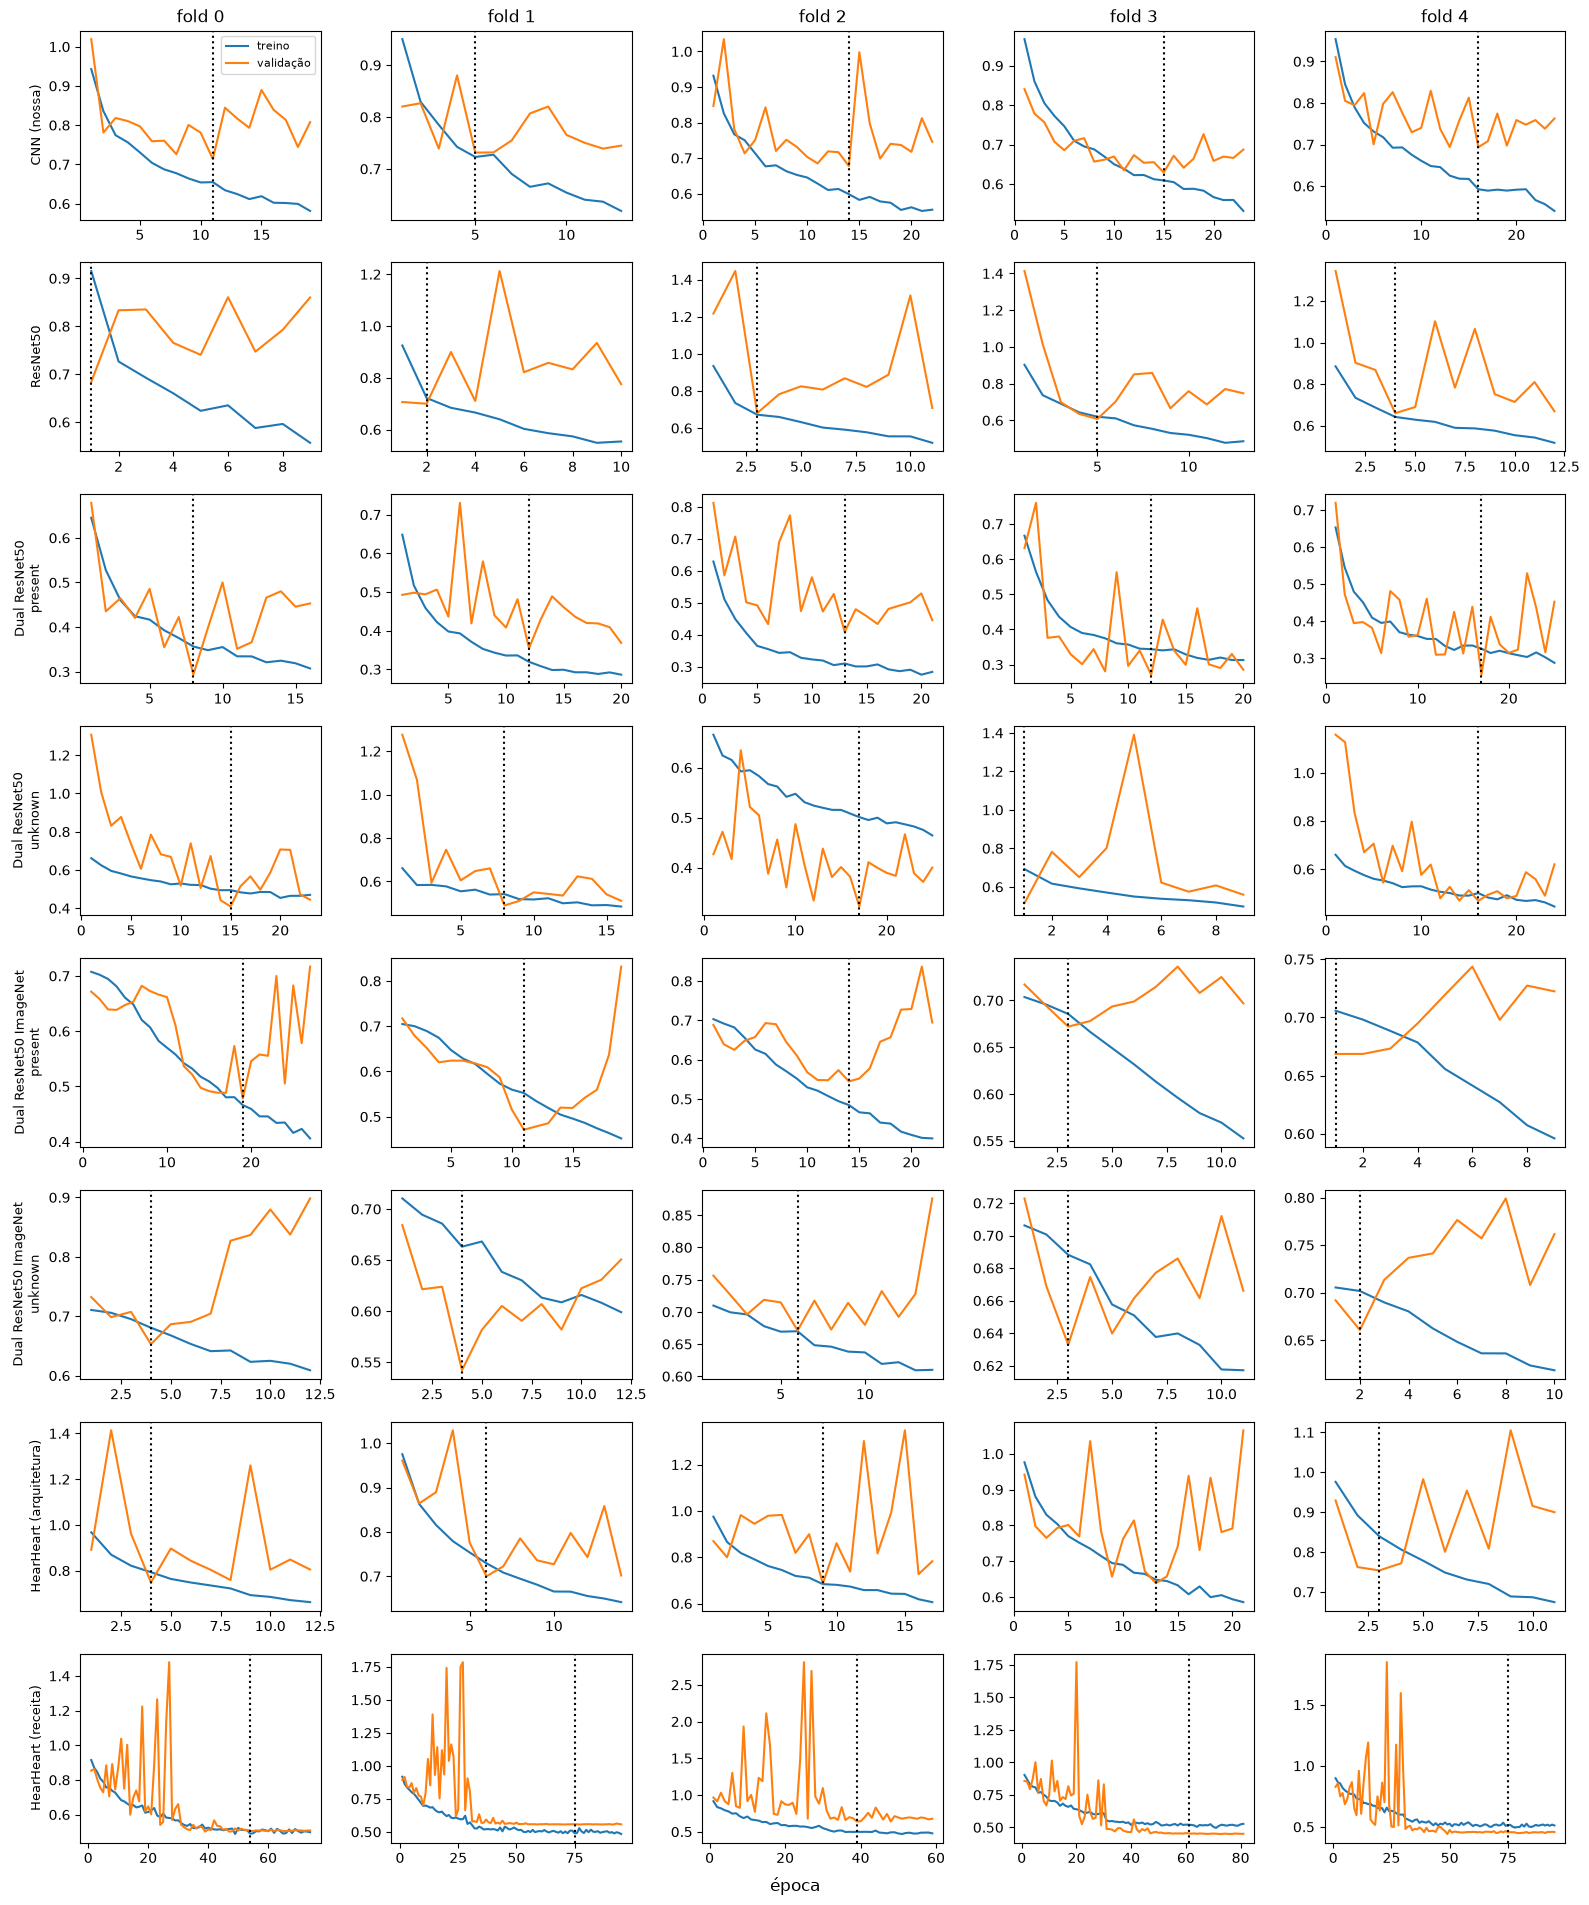

In [4]:
curves = [(n, head) for n, r in runs.items() if n in MODELS for head in sorted({h for h, _ in r['hist']})]
folds = sorted({k for r in runs.values() for _, k in r['hist']})
fig, axes = plt.subplots(len(curves), len(folds), figsize=(3.2 * len(folds), 2.4 * len(curves)), squeeze=False)
for i, (n, head) in enumerate(curves):
    for j, k in enumerate(folds):
        ax, h = axes[i, j], runs[n]['hist'].get((head, k))
        if h is None:
            ax.axis('off'); continue
        ax.plot(h.epoch + 1, h.train_loss, label='treino'); ax.plot(h.epoch + 1, h.val_loss, label='validação')
        ax.axvline(best_epoch(h) + 1, ls=':', c='k')
        if i == 0: ax.set_title(f'fold {k}')
        if j == 0: ax.set_ylabel(f'{n}\n{head}' if head != 'multiclass' else n, fontsize=9)
axes[0, 0].legend(fontsize=8); fig.supxlabel('época'); plt.tight_layout()

In [5]:
rows = []
for n, head in curves:
    for (h_, k), h in runs[n]['hist'].items():
        if h_ != head: continue
        b = best_epoch(h)
        rows.append({'modelo': n, 'rede': head, 'fold': k, 'melhor época': b + 1, 'épocas treinadas': len(h),
                     'train loss': h.train_loss[b], 'val loss': h.val_loss[b],
                     'val/train': h.val_loss[b] / h.train_loss[b]})
ep = pd.DataFrame(rows)
ep.groupby(['modelo', 'rede'], sort=False)[['melhor época', 'épocas treinadas', 'val/train']].agg(['mean', 'min', 'max']).round(2)

melhor época         épocas treinadas         val/train            
                                           mean min max             mean min max      mean   min   max
modelo                  rede                                                                          
CNN (nossa)             multiclass         12.2   5  16             20.2  13  24      1.09  1.01  1.17
ResNet50                multiclass          3.0   1   5             11.0   9  13      0.95  0.75  1.03
Dual ResNet50           present            12.4   8  17             20.4  16  25      0.96  0.78  1.32
                        unknown            11.4   1  17             19.4   9  25      0.81  0.64  0.94
Dual ResNet50 ImageNet  present             9.6   1  19             17.6   9  27      0.99  0.85  1.12
                        unknown             3.8   2   6             11.8  10  14      0.93  0.82  1.00
HearHeart (arquitetura) multiclass          7.0   3  13             15.0  11  21      0.96  0.90  1.00
HearHeart (receita)     multiclass         60.8  39  75             80.8  59  95      1.04  0.87  1.28

**Leitura.** `melhor época` baixa (1–3) e `val/train` muito acima de 1 indicam que a rede decora o treino depressa.
Na CNN a melhor época fica por volta de 10–16; é a referência para as ResNet.

## 4. Avaliação por paciente

Para cada modelo: agregação `max` por paciente, regra hierárquica *Present* → *Unknown* → *Absent* e limiares de cada
fold afinados **só nos outros folds** (`cv_report`), tal como na CNN e na MLP.

In [6]:
AGG = 'max'
res = {}
for n, r in runs.items():
    pat = patient_scores(r['dev'], r['oof'], how=AGG)
    table, pred, rep = cv_report(pat)
    res[n] = {'pat': pat, 'table': table, 'rep': rep}

summary_tab = pd.DataFrame({
    n: {'parâmetros (M)': N_PARAMS[runs[n]['folder']] / 1e6,
        'WA média': x['table']['WA (tuned)'].mean(), 'WA dp': x['table']['WA (tuned)'].std(),
        'WA pooled': x['rep']['weighted_accuracy'],
        **{f'recall {c}': x['rep']['recall'][c] for c in CLASSES},
        't_present médio': x['table'].t_present.mean(), 't_unknown médio': x['table'].t_unknown.mean()}
    for n, x in res.items()}).T
summary_tab.round(3)

,parâmetros (M),WA média,WA dp,WA pooled,recall Present,recall Unknown,recall Absent,t_present médio,t_unknown médio
CNN (nossa),0.106,0.767,0.021,0.767,0.783,0.333,0.872,0.500,0.725
ResNet50,23.508,0.756,0.038,0.756,0.839,0.148,0.826,0.345,0.720
Dual ResNet50,47.016,0.758,0.034,0.758,0.825,0.111,0.860,0.470,0.775
Dual ResNet50 ImageNet,47.016,0.623,0.069,0.622,0.713,0.037,0.676,0.525,0.605
HearHeart (arquitetura),0.038,0.715,0.051,0.715,0.699,0.481,0.802,0.415,0.555
HearHeart (receita),0.038,0.750,0.030,0.749,0.776,0.167,0.885,0.635,0.395
MLP (referência),0.060,0.648,0.026,0.648,0.706,0.296,0.676,0.475,0.700


### WA fold a fold

Todos os modelos usam **os mesmos folds**, por isso a comparação justa é dentro de cada fold: quantas vezes cada
ResNet ganha à CNN, e por quanto. Ganhar em 5 de 5 folds é um sinal muito mais forte do que uma média 0.01 acima,
porque o desvio padrão entre folds (~0.02) é maior do que essas diferenças.

In [7]:
wa = pd.DataFrame({n: x['table']['WA (tuned)'] for n, x in res.items()})
display(wa.round(3))
base = 'CNN (nossa)'
cmp = pd.DataFrame({n: {'diferença média': round((wa[n] - wa[base]).mean(), 3),
                        'folds em que ganha à CNN': f"{int((wa[n] > wa[base]).sum())}/{len(wa)}",
                        'pior fold': round((wa[n] - wa[base]).min(), 3),
                        'melhor fold': round((wa[n] - wa[base]).max(), 3)}
                    for n in wa if n != base}).T
cmp

,CNN (nossa),ResNet50,Dual ResNet50,Dual ResNet50 ImageNet,HearHeart (arquitetura),HearHeart (receita),MLP (referência)
fold,,,,,,,
0,0.734,0.696,0.709,0.647,0.654,0.716,0.668
1,0.758,0.747,0.740,0.600,0.698,0.765,0.618
2,0.778,0.764,0.771,0.718,0.785,0.722,0.630
3,0.782,0.775,0.799,0.619,0.744,0.758,0.682
4,0.783,0.797,0.769,0.528,0.692,0.787,0.643


,diferença média,folds em que ganha à CNN,pior fold,melhor fold
ResNet50,-0.011,1/5,-0.038,0.014
Dual ResNet50,-0.009,1/5,-0.024,0.017
Dual ResNet50 ImageNet,-0.144,0/5,-0.255,-0.06
HearHeart (arquitetura),-0.052,1/5,-0.091,0.007
HearHeart (receita),-0.017,2/5,-0.056,0.007
MLP (referência),-0.119,0/5,-0.148,-0.066


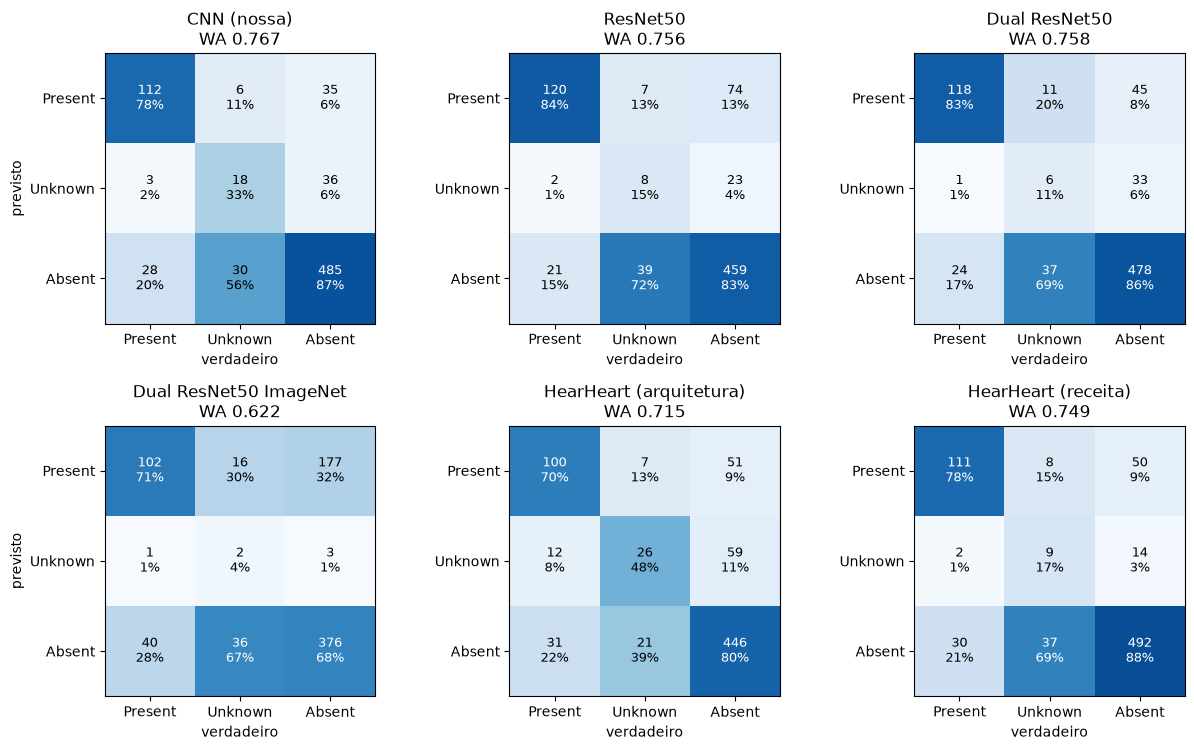

In [8]:
names = [n for n in res if n in MODELS]
ncol = 3
fig, axes = plt.subplots(-(-len(names) // ncol), ncol, figsize=(4.2 * ncol, 3.8 * -(-len(names) // ncol)), squeeze=False)
for ax in axes.flat[len(names):]:
    ax.axis('off')
for ax, n in zip(axes.flat, names):
    m = res[n]['rep']['confusion']              # linhas = previsto, colunas = verdadeiro
    rec = m / m.sum(0, keepdims=True)
    ax.imshow(rec, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{m[i, j]}\n{rec[i, j]:.0%}', ha='center', va='center',
                    color='white' if rec[i, j] > 0.6 else 'black', fontsize=9)
    ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='verdadeiro', title=f"{n}\nWA {res[n]['rep']['weighted_accuracy']:.3f}")
for row in axes: row[0].set_ylabel('previsto')
plt.tight_layout()

Matrizes por paciente (todos os folds juntos); a percentagem é a fração de cada classe verdadeira (coluna), por isso
a diagonal é o recall. Os erros mais caros são os *Present* previstos como *Absent* (peso 5).

### Com a regra de decisão do HearHeart

O HearHeart não usa limiares: cada gravação recebe a classe de maior probabilidade e o paciente é *Absent* se todas
as gravações forem *Absent*, *Present* se alguma for *Present*, e *Unknown* nos outros casos. Aplicamos esta regra a
**todos** os modelos, para separar o efeito do modelo do efeito da regra de decisão. Como a regra não tem parâmetros
afinados, não precisa de validação cruzada encadeada.

In [9]:
def hh_rule(dev, oof):
    p = pd.DataFrame(oof, columns=CLASSES, index=dev.index)
    p['recording'], p['pid'], p['fold'], p['true'] = dev.recording, dev.patient_id, dev.fold, dev.murmur
    rec = p.groupby('recording').agg({**{c: 'mean' for c in CLASSES}, 'pid': 'first', 'fold': 'first', 'true': 'first'})
    rec['pred'] = np.array(CLASSES)[rec[CLASSES].to_numpy().argmax(1)]
    rule = lambda x: 'Absent' if (x == 'Absent').all() else 'Present' if (x == 'Present').any() else 'Unknown'
    pat = rec.groupby('pid').agg(fold=('fold', 'first'), true=('true', 'first'), pred=('pred', rule))
    return pd.Series({k: report(x.true, x.pred)['weighted_accuracy'] for k, x in pat.groupby('fold')}), report(pat.true, pat.pred)

rule_rows = {}
for n, r in runs.items():
    wa_f, rep_r = hh_rule(r['dev'], r['oof'])
    rule_rows[n] = {'WA limiares (nossa)': res[n]['table']['WA (tuned)'].mean(), 'WA regra HearHeart': wa_f.mean(),
                    'dp regra': wa_f.std(), **{f'recall {c} (regra)': rep_r['recall'][c] for c in CLASSES}}
pd.DataFrame(rule_rows).T.round(3)

,WA limiares (nossa),WA regra HearHeart,dp regra,recall Present (regra),recall Unknown (regra),recall Absent (regra)
CNN (nossa),0.767,0.674,0.057,0.790,0.722,0.509
ResNet50,0.756,0.717,0.032,0.755,0.630,0.692
Dual ResNet50,0.758,0.734,0.057,0.825,0.574,0.664
Dual ResNet50 ImageNet,0.623,0.512,0.046,0.874,0.444,0.067
HearHeart (arquitetura),0.715,0.684,0.061,0.699,0.685,0.664
HearHeart (receita),0.750,0.763,0.029,0.874,0.185,0.790
MLP (referência),0.648,0.523,0.039,0.748,0.611,0.209


**Atenção ao comparar a receita HearHeart (A):** o early stopping escolhe a época com maior WA *no próprio fold de
validação*, o que torna os números de A ligeiramente otimistas. Os outros modelos escolhem a época pela perda de
validação, uma escolha menos diretamente ligada à métrica.

## 5. Conclusões e escolha do modelo final

Perguntas a responder com os resultados acima:

1. **Run 1 vs CNN** — com o mesmo treino, uma rede 220× maior ganha? Se não, com ~600 pacientes de treino por fold
   a capacidade extra não compensa. (Atenção: usámos os hiperparâmetros da CNN, que podem não ser os melhores para a
   ResNet; a conclusão é "com o mesmo treino", não "a ResNet50 é pior".)
2. **Run 2 vs run 1** — dividir em dois binários melhora o recall de *Unknown* (0.33 na CNN)?
3. **Run 3 vs run 2** — o pré-treino dá curvas mais estáveis (melhor época mais tarde, `val/train` menor) e melhor WA?
4. **HearHeart B vs CNN** — com a mesma entrada e o mesmo treino, a arquitetura do vencedor é melhor do que a nossa?
5. **HearHeart A vs B** — a entrada (15 s, até 2 kHz) e o treino do vencedor fazem diferença?

**Regra de escolha, definida antes de ver os resultados:** fica o modelo de maior WA média **se ganhar à CNN por mais
de 0.02** (cerca de um desvio padrão entre folds); caso contrário fica a CNN, que é mais simples e mais barata.

In [10]:
best = summary_tab.loc[[n for n in summary_tab.index if n in MODELS], 'WA média'].idxmax()
gain = summary_tab.loc[best, 'WA média'] - summary_tab.loc[base, 'WA média']
CHOSEN = best if gain > 0.02 else base
print(f'melhor WA média: {best} ({gain:+.3f} face à CNN) -> modelo escolhido: {CHOSEN}')

t_final, wa_oof = tune_thresholds(res[CHOSEN]['pat'])
print('limiares finais (todos os folds): t_present = %.3f, t_unknown = %.3f (WA OOF %.3f, otimista)' % (*t_final, wa_oof))

melhor WA média: CNN (nossa) (+0.000 face à CNN) -> modelo escolhido: CNN (nossa)
limiares finais (todos os folds): t_present = 0.500, t_unknown = 0.725 (WA OOF 0.767, otimista)


## 6. Teste — correr só uma vez, no fim

Ensemble dos 5 modelos dos folds sobre os pacientes de teste (fold −1), com os limiares finais acima. Só se corre
depois de o modelo estar escolhido; o resultado reporta-se tal como sair. Para uma ResNet *dual* em CPU, as 30
passagens MC demoram ~1 h; com GPU são segundos.

In [11]:
RUN_TEST = False
if RUN_TEST:
    te = (d.windows.fold == -1).to_numpy()
    folder = runs[CHOSEN]['folder']
    if folder == 'cnn':
        from src.cnn import DEFAULT_CNN_CFG, load_runs as load_cnn, predict_ensemble_cnn
        probs = predict_ensemble_cnn(load_cnn(RESULTS_DIR / folder), d, te, DEFAULT_CNN_CFG)
    else:
        from src.resnet import load_runs as load_resnet, predict_ensemble_resnet
        fold_runs, cfg = load_resnet(RESULTS_DIR / folder)
        probs = predict_ensemble_resnet(fold_runs, d, te, cfg | {'num_workers': 0})
    pat_te = patient_scores(d.windows[te], probs, how=AGG)
    r = report(pat_te.murmur, predict_rule(pat_te, *t_final))
    print(f'{CHOSEN} — TESTE WA = %.3f' % r['weighted_accuracy'], {c: round(v, 3) for c, v in r['recall'].items()})
    display(confusion_df(r))